# 00 · First look at the data

**Project:** Solar Energy Potential in Gjilan: Applying Calculus and Machine Learning to Real Radiation Data
**Milestone:** M0 (HW1, idea presentation)

This notebook loads the cached raw data, checks that it is complete, and draws the first real-data charts.
No course math yet: sun geometry, Newton's method, integration and optimization start in M1–M3.

All logic lives in the `solar_gjilan` package (`src/solar_gjilan/`); this notebook only calls it.
Data must be downloaded once first: `uv run python -m solar_gjilan.download`.

In [1]:
import pandas as pd
from solar_gjilan import config as cfg, data, plots

print(f"Location: {cfg.LAT}° N, {cfg.LON}° E ({cfg.TZ}); period {cfg.START_YEAR}–{cfg.END_YEAR}")
print(f"Default system: {cfg.PEAK_KWP:g} kWp, {cfg.LOSS_PCT:g} % losses")

Location: 42.46° N, 21.47° E (Europe/Belgrade); period 2005–2023
Default system: 5 kWp, 14 % losses


## 1. Data sources

| File (`data/raw/`) | Source | Role | Content |
|---|---|---|---|
| `pvgis/input/hourly_horizontal_2005_2023.csv` | PVGIS-SARAH3 (EU JRC), satellite-derived | input | hourly beam/diffuse irradiance on a flat surface, sun height, modelled PV power for 5 kWp |
| `pvgis/reference/hourly_tilt35_2005_2023.csv` | same | reference | same, on a 35° south-facing plane (used later to validate our own calculations) |
| `pvgis/reference/pvcalc_optimal.json` | PVGIS official estimate | reference | long-term yearly kWh and the optimal tilt |
| `openmeteo/era5_hourly_2005_2023.csv` | Open-Meteo, ERA5 reanalysis | input | temperature, humidity, cloud cover, wind, radiation |

All timestamps are UTC. PVGIS values are stamped at minute 10 of each hour.

Column meanings and units: `data/README.md`.

In [2]:
flat = data.load_pvgis_hourly(0)
tilted = data.load_pvgis_hourly(cfg.REF_TILT)
weather = data.load_openmeteo_hourly()
flat.head()

,P_W,Gb,Gd,Gr,sun_height,T2m,WS10m,reconstructed,G_poa
time,,,,,,,,,
2005-01-01 00:10:00+00:00,0.0,0.0,0.0,0.0,0.0,0.73,1.03,False,0.0
2005-01-01 01:10:00+00:00,0.0,0.0,0.0,0.0,0.0,0.79,1.03,False,0.0
2005-01-01 02:10:00+00:00,0.0,0.0,0.0,0.0,0.0,0.61,1.17,False,0.0
2005-01-01 03:10:00+00:00,0.0,0.0,0.0,0.0,0.0,0.42,1.17,False,0.0
2005-01-01 04:10:00+00:00,0.0,0.0,0.0,0.0,0.0,0.49,1.10,False,0.0


In [3]:
weather.head()

,temperature_2m,relative_humidity_2m,cloud_cover,wind_speed_10m,shortwave_radiation,direct_radiation,diffuse_radiation
time,,,,,,,
2005-01-01 00:00:00+00:00,3.1,88,96,5.5,0.0,0.0,0.0
2005-01-01 01:00:00+00:00,3.4,88,97,5.5,0.0,0.0,0.0
2005-01-01 02:00:00+00:00,3.0,89,98,6.0,0.0,0.0,0.0
2005-01-01 03:00:00+00:00,3.1,90,95,6.3,0.0,0.0,0.0
2005-01-01 04:00:00+00:00,3.0,89,99,5.7,0.0,0.0,0.0


## 2. Is the data complete?

A 19-year hourly series has 19 × 8760 + 4 leap days × 24 = 166,536 hours. We check for missing or duplicated hours, NaN values, and how many radiation values PVGIS had to reconstruct.

In [4]:
pd.DataFrame({
    "PVGIS flat": data.quick_summary(flat),
    "PVGIS 35°": data.quick_summary(tilted),
    "Open-Meteo ERA5": data.quick_summary(weather),
}).T

,rows,start,end,missing_hours,duplicate_hours,nan_values,reconstructed_pct
PVGIS flat,166536,2005-01-01 00:10:00+00:00,2023-12-31 23:10:00+00:00,0,0,0,0.0
PVGIS 35°,166536,2005-01-01 00:10:00+00:00,2023-12-31 23:10:00+00:00,0,0,0,0.0
Open-Meteo ERA5,166536,2005-01-01 00:00:00+00:00,2023-12-31 23:00:00+00:00,0,0,0,NaN


In [5]:
official = data.load_pvcalc("optimal")
official

{'tilt': 35,
 'azimuth': -1,
 'E_y': 6554.03,
 'E_d': 17.96,
 'H_y': 1680.92,
 'SD_y': 257.37,
 'l_total': -22.02}

## 3. A sunny summer day vs a sunny winter day

The sunniest June and December days of 2023 (highest daily irradiation) are picked automatically.
Daily energy here is a simple sum of hourly values (P · 1 h); the proper integration rules (trapezoid, Simpson) come in M2.

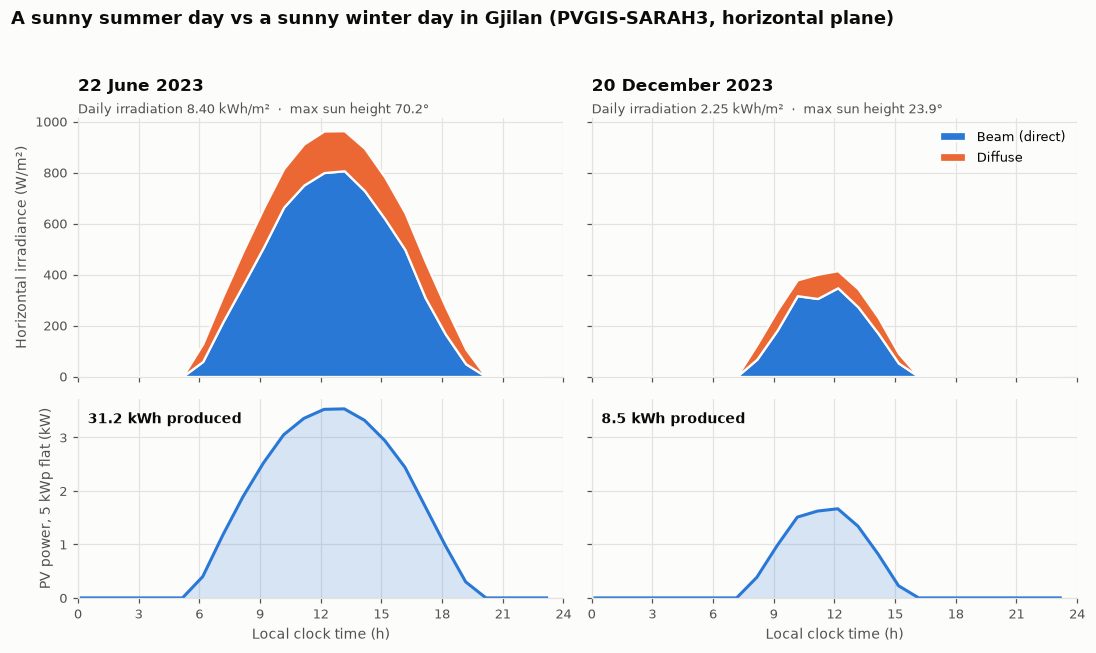

In [6]:
summer = data.sunniest_day(flat, 2023, 6)
winter = data.sunniest_day(flat, 2023, 12)
fig = plots.summer_vs_winter_day(flat, summer, winter)

## 4. Production across the year

Mean daily energy per month for a flat panel and a 35° south-facing panel. The band shows the lowest and highest year.

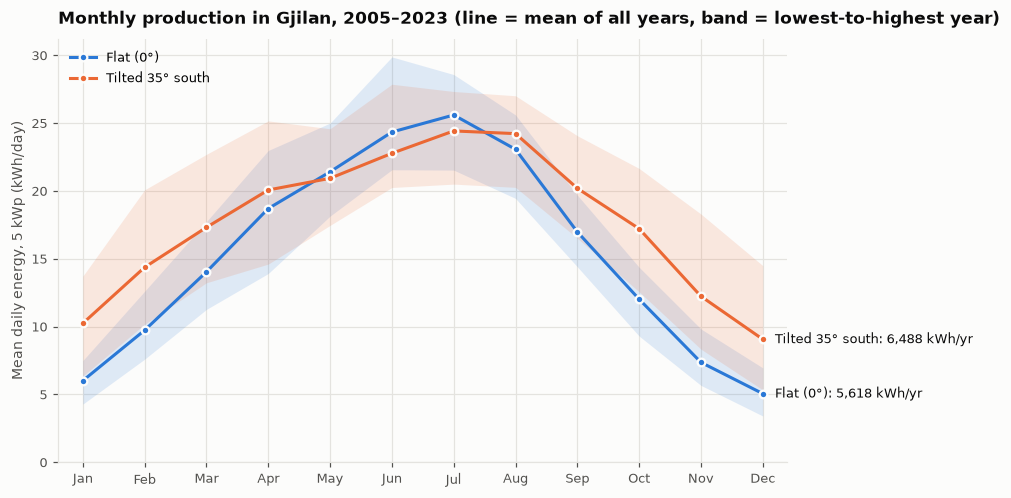

In [7]:
fig = plots.monthly_energy(flat, tilted, cfg.REF_TILT)

In [8]:
yearly = {
    "flat (0°)": data.daily_energy(flat).sum() / 19,
    f"tilted {cfg.REF_TILT}°": data.daily_energy(tilted).sum() / 19,
}
gain = 100 * (yearly[f"tilted {cfg.REF_TILT}°"] / yearly["flat (0°)"] - 1)
print({k: round(v) for k, v in yearly.items()}, f"→ tilt gain {gain:.1f} %")
print(f"PVGIS official estimate at optimal tilt {official['tilt']}°: {official['E_y']:.0f} kWh/yr")

{'flat (0°)': 5618, 'tilted 35°': 6488} → tilt gain 15.5 %
PVGIS official estimate at optimal tilt 35°: 6554 kWh/yr


## 5. Every day of 19 years

Each pixel is one day's irradiation on a horizontal surface. The seasonal pattern dominates; vertical light streaks are cloudy spells. The palest summer days (e.g. May 2008) are not clouds but missing satellite data that PVGIS stores as 0 (see below).

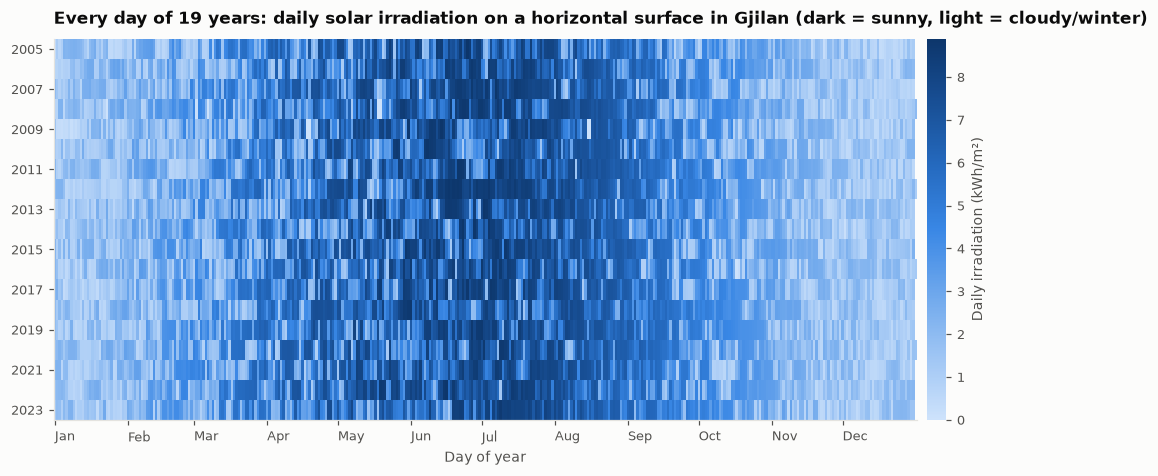

In [9]:
fig = plots.irradiation_heatmap(flat)

## What this tells us, and what comes next

- No rows are missing and nothing is empty, but **PVGIS stores 437 daylight hours of missing satellite data as 0** (14 full days plus scattered hours, about 0.5 % of the yearly energy). `quick_summary` cannot see this; it is found by comparing with the computed sun position (details in `data/README.md`) and is handled in M1.
- Tilting the panel 35° toward the south increases yearly energy. In June and July a flat panel actually produces more, because the sun is high; in winter the tilted panel wins clearly.
- Our yearly sum for the 35° series agrees with the official PVGIS estimate to about 1 %.

**M1 (HW2):** clean and align the two sources, compute the sun position with trigonometry, find sunrise and sunset with Newton's method, and compare our sun height with PVGIS's `sun_height`.